Original Dataset Shape: (178, 13)
Reduced Dataset Shape: (178, 2)


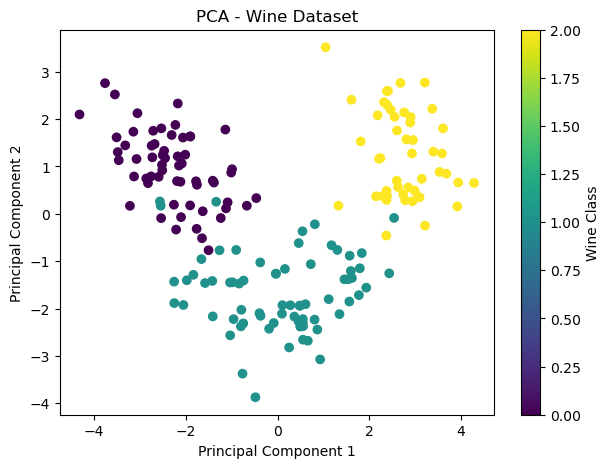

Reconstruction Error: 0.4459366164306473

Explained Variance Ratio:
[0.36198848 0.1920749 ]
Total Variance Explained: 55.40633835693527 %

Sklearn PCA Shape: (178, 2)
Sklearn Explained Variance Ratio: [0.36198848 0.1920749 ]
Sklearn Total Variance Explained: 55.40633835693527 %


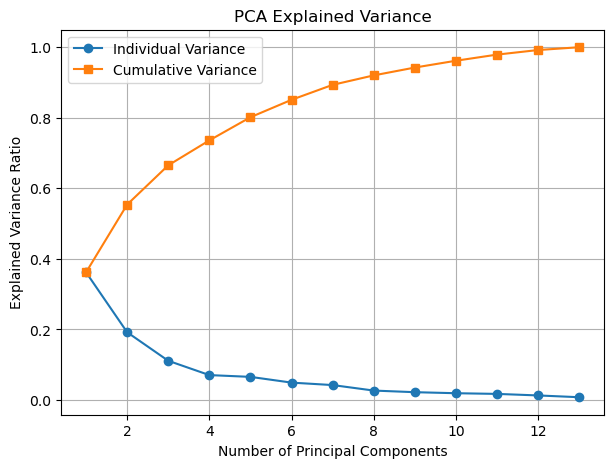

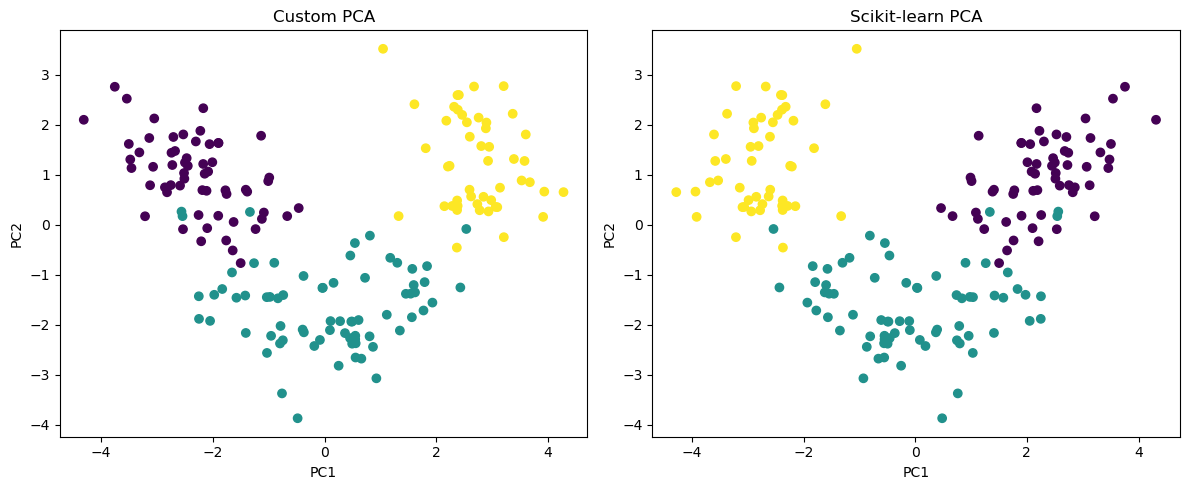

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Step 1: Load Wine dataset
wine = load_wine()
X = wine.data
y = wine.target

print("Original Dataset Shape:", X.shape)

# Step 2: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Calculate covariance matrix
cov_matrix = np.cov(X_scaled.T)

# Step 4: Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Step 5: Sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Step 6: Select first two principal components
components = eigenvectors[:, :2]

# Step 7: Project data onto 2D
X_pca = X_scaled @ components

print("Reduced Dataset Shape:", X_pca.shape)

# Step 8: Visualize reduced data
plt.figure(figsize=(7, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Dataset")
plt.colorbar(label="Wine Class")
plt.show()

# Step 9: Reconstruct original data
X_reconstructed = X_pca @ components.T

# Calculate reconstruction error
error = np.mean((X_scaled - X_reconstructed) ** 2)

print("Reconstruction Error:", error)

# Step 10: Calculate explained variance ratio
explained_variance = eigenvalues / np.sum(eigenvalues)

print("\nExplained Variance Ratio:")
print(explained_variance[:2])

print("Total Variance Explained:",
      np.sum(explained_variance[:2]) * 100, "%")

# Step 11: Compare with Scikit-learn PCA
pca = PCA(n_components=2)

X_sklearn = pca.fit_transform(X_scaled)

print("\nSklearn PCA Shape:", X_sklearn.shape)

print("Sklearn Explained Variance Ratio:",
      pca.explained_variance_ratio_)

print("Sklearn Total Variance Explained:",
      sum(pca.explained_variance_ratio_) * 100, "%")

# Step 12: Plot explained variance
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o',
    label='Individual Variance'
)

plt.plot(
    range(1, len(explained_variance) + 1),
    np.cumsum(explained_variance),
    marker='s',
    label='Cumulative Variance'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid()
plt.show()

# Step 13: Compare custom PCA and sklearn PCA
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.title("Custom PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(X_sklearn[:, 0], X_sklearn[:, 1], c=y, cmap='viridis')
plt.title("Scikit-learn PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()
